In [1]:
import pandas as pd
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path

In [2]:
#specifing datapath
Data_path=Path(r"C:\\Users\\User\\Downloads\\Video Game Sales dataset\\Video_Games_Sales_as_at_22_Dec_2016.csv")
# checking if file exit in the path location 
if not Data_path.exists():
    raise FileNotFoundError("CSV not found in the given file path  please check the file path ")
#load the dataset
df=pd.read_csv(Data_path)




In [3]:
#shape of the dataset
print("shape:",df.shape)


shape: (16719, 16)


In [4]:
#prints summary of coln 
display(df.info())


<class 'pandas.DataFrame'>
RangeIndex: 16719 entries, 0 to 16718
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Name             16717 non-null  str    
 1   Platform         16719 non-null  str    
 2   Year_of_Release  16450 non-null  float64
 3   Genre            16717 non-null  str    
 4   Publisher        16665 non-null  str    
 5   NA_Sales         16719 non-null  float64
 6   EU_Sales         16719 non-null  float64
 7   JP_Sales         16719 non-null  float64
 8   Other_Sales      16719 non-null  float64
 9   Global_Sales     16719 non-null  float64
 10  Critic_Score     8137 non-null   float64
 11  Critic_Count     8137 non-null   float64
 12  User_Score       7590 non-null   float64
 13  User_Count       7590 non-null   float64
 14  Developer        10096 non-null  str    
 15  Rating           9950 non-null   str    
dtypes: float64(10), str(6)
memory usage: 2.9 MB


None

In [5]:
#generate descriptive statistics summary
display(df.describe())

,Year_of_Release,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Critic_Score,Critic_Count,User_Score,User_Count
count,16450.000000,16719.000000,16719.000000,16719.000000,16719.000000,16719.000000,8137.000000,8137.000000,7590.000000,7590.000000
mean,2006.487356,0.263330,0.145025,0.077602,0.047332,0.533543,68.967679,26.360821,7.125046,162.229908
std,5.878995,0.813514,0.503283,0.308818,0.186710,1.547935,13.938165,18.980495,1.500006,561.282326
min,1980.000000,0.000000,0.000000,0.000000,0.000000,0.010000,13.000000,3.000000,0.000000,4.000000
25%,2003.000000,0.000000,0.000000,0.000000,0.000000,0.060000,60.000000,12.000000,6.400000,10.000000
50%,2007.000000,0.080000,0.020000,0.000000,0.010000,0.170000,71.000000,21.000000,7.500000,24.000000
75%,2010.000000,0.240000,0.110000,0.040000,0.030000,0.470000,79.000000,36.000000,8.200000,81.000000
max,2020.000000,41.360000,28.960000,10.220000,10.570000,82.530000,98.000000,113.000000,9.700000,10665.000000


In [6]:
df.head()

,Name,Platform,Year_of_Release,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Critic_Score,Critic_Count,User_Score,User_Count,Developer,Rating
0,Wii Sports,Wii,2006.0,Sports,Nintendo,41.36,28.96,3.77,8.45,82.53,76.0,51.0,8.0,322.0,Nintendo,E
1,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24,NaN,NaN,NaN,NaN,NaN,NaN
2,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.68,12.76,3.79,3.29,35.52,82.0,73.0,8.3,709.0,Nintendo,E
3,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.61,10.93,3.28,2.95,32.77,80.0,73.0,8.0,192.0,Nintendo,E
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37,NaN,NaN,NaN,NaN,NaN,NaN


## Checking out for missing values and duplicates

In [7]:
missing_details=pd.DataFrame({
'missing_count':df.isnull().sum(),
'missing_percentage':(df.isnull().mean()*100).round(2)
}
).sort_values('missing_percentage',ascending=True)
display(missing_details[missing_details['missing_count']>0])

,missing_count,missing_percentage
Name,2,0.01
Genre,2,0.01
Publisher,54,0.32
Year_of_Release,269,1.61
Developer,6623,39.61
Rating,6769,40.49
Critic_Count,8582,51.33
Critic_Score,8582,51.33
User_Count,9129,54.60
User_Score,9129,54.60


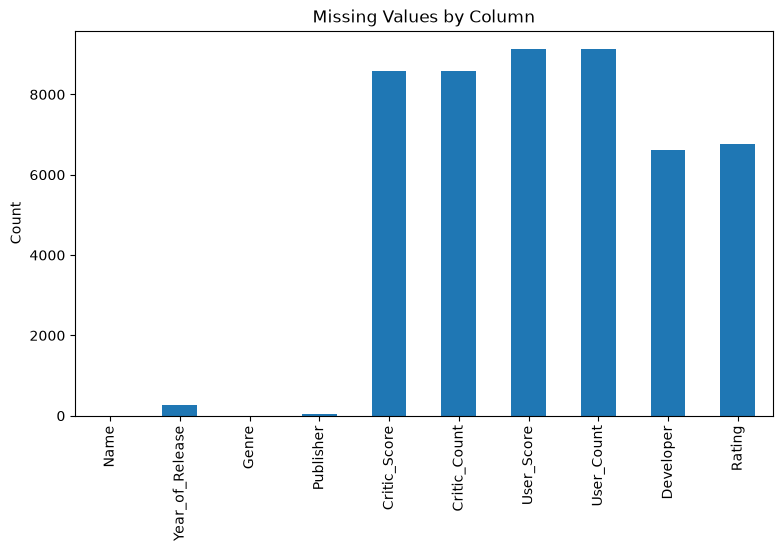

In [8]:
#checking
missing = df.isnull().sum()

missing = missing[missing > 0]

missing.plot(kind='bar', figsize=(9, 5))

plt.title('Missing Values by Column')
plt.ylabel('Count')
plt.show()

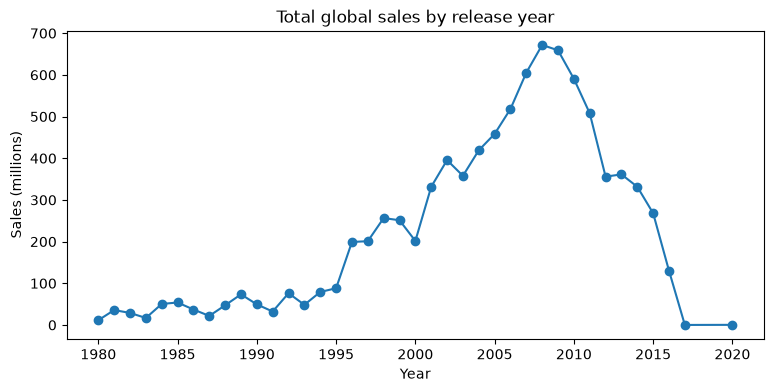

In [9]:
df.groupby("Year_of_Release")["Global_Sales"].sum().plot(kind="line", marker="o", figsize=(9, 4))
plt.title("Total global sales by release year")
plt.xlabel("Year")
plt.ylabel("Sales (millions)")
plt.show()

In [10]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


Since no duplicate rows, so no need to find and remove duplicate rows

## 3. Data cleaning and validation
Use this order:
1. Inspect the raw data: check columns, types, missing values, and duplicates.
2. Remove exact duplicate rows.
3. Fix data types: convert year, scores, counts, and sales to numeric. Values like "tbd" in User_Score will become missing.
4. Clean invalid values: check for impossible score ranges, negative sales, suspicious release years, and inconsistent category text. Correct values when you can; otherwise mark them missing or document why you remove a row.
5. Remove rows missing Global_Sales: it’s the value you want to predict, so rows without it can’t train the model.
6. Handle rows missing Name: remove them if you need game names for your analysis. Name is not a predictor in the current notebook, so this choice is about data quality and reporting.
7. Keep missing predictor values for now. Don’t delete those rows automatically.
8. Split into training and test sets.
9. Fill missing predictors using training data only: numeric values with training-set medians, and missing categories with "Unknown". Apply the same fill values to the test set.
10. Check the cleaned data: confirm duplicates and invalid values are handled, the target has no missing values, and predictors are ready for modeling.
So, cleaning starts with inspection, duplicates, types, and invalid values. Filling predictor gaps is a later preprocessing step, after the split.

In [11]:
numeric_coln=df.select_dtypes('number').columns.tolist()
print(numeric_coln)

['Year_of_Release', 'NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales', 'Global_Sales', 'Critic_Score', 'Critic_Count', 'User_Score', 'User_Count']


In [12]:
for i in numeric_coln:
    if i in df.columns:
        df[i]=pd.to_numeric(df[i],errors='coerce') #errors='coerce' means the data that cant be converted will be missing value

In [13]:
df.select_dtypes('number').columns

Index(['Year_of_Release', 'NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales',
       'Global_Sales', 'Critic_Score', 'Critic_Count', 'User_Score',
       'User_Count'],
      dtype='str')

In [14]:
df[['User_Score', 'Critic_Score']].isna().sum()

User_Score      9129
Critic_Score    8582
dtype: int64

In [15]:
# user_score range is 0-10 anything above or less is invalid 
#replacing them with nan
df.loc[
    ~df.User_Score.between(0,10),'User_Score'
]=np.nan

## Critic_score range is 0-100 anything above or less is invalid
df.loc[
    ~df.Critic_Score.between(0,100),'Critic_Score'
]=np.nan

In [16]:
df[['User_Score', 'Critic_Score']].isna().sum()

User_Score      9129
Critic_Score    8582
dtype: int64

In [17]:
df[['Critic_Count','User_Count']].isna().sum()

Critic_Count    8582
User_Count      9129
dtype: int64

In [18]:
#count cant be negative so checking and replacing it as nan if its negative
for i in ['Critic_Count','User_Count']:
    if i in df.columns:
        df.loc[df[i]<0,i]=np.nan

In [19]:
sales_coln=['NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales', 'Global_Sales']
for col in sales_coln:
    if col in df.columns:
        df.loc[df[col]<0,col]=np.nan

In [20]:
df.Year_of_Release

0        2006.0
1        1985.0
2        2008.0
3        2009.0
4        1996.0
          ...  
16714    2016.0
16715    2006.0
16716    2016.0
16717    2003.0
16718    2016.0
Name: Year_of_Release, Length: 16719, dtype: float64

In [21]:
# we remove rows having missing global sales value as its our target
if 'Global_Sales' not in df.columns:#check if column present in dataset
    raise KeyError('no Global_Sales column in the dataset')
rows_before=len(df)
df=df.dropna(subset=['Global_Sales']).copy()
print(f"Rows removed from the dataset without Global_Sales value:{rows_before-len(df)}")


Rows removed from the dataset without Global_Sales value:0


In [22]:
df.Name.shape

(16719,)

In [23]:
#dropping rows with missing Name
if 'Name' in df.columns:
    rows_before=len(df)
    df=df.dropna(subset=['Name']).copy()
    print(f"Rows removed without game name:{rows_before-len(df)}")
    

Rows removed without game name:2


In [24]:
missing_details=pd.DataFrame({
'missing_count':df.isnull().sum(),
'missing_percentage':(df.isnull().mean()*100).round(2)
}
).sort_values('missing_percentage',ascending=True)
display(missing_details[missing_details['missing_count']>0])

,missing_count,missing_percentage
Publisher,54,0.32
Year_of_Release,269,1.61
Developer,6621,39.61
Rating,6767,40.48
Critic_Count,8580,51.32
Critic_Score,8580,51.32
User_Count,9127,54.60
User_Score,9127,54.60


In [25]:
if "Year_of_Release" in df.columns:
    print("\nRelease-year summary:")
    print(df["Year_of_Release"].describe())

    print("\nMissing release years:",
          df["Year_of_Release"].isna().sum())


Release-year summary:
count    16448.000000
mean      2006.488996
std          5.877470
min       1980.000000
25%       2003.000000
50%       2007.000000
75%       2010.000000
max       2020.000000
Name: Year_of_Release, dtype: float64

Missing release years: 269


In [26]:
# # Fill missing categorical values with mode

# categorical_columns = [
#     "Platform",
#     "Genre",
#     "Publisher",
#     "Rating"
# ]

# for col in categorical_columns:
#     df[col] = df[col].fillna(df[col].mode()[0])
    
# missing_details=pd.DataFrame({
# 'missing_count':df.isnull().sum(),
# 'missing_percentage':(df.isnull().mean()*100).round(2)
# }
# ).sort_values('missing_percentage',ascending=True)
# display(missing_details[missing_details['missing_count']>0])


In [27]:
# categorical_columns = [
#     "Platform",
#     "Genre",
#     "Publisher",
#     "Rating",
#     "Developer"
# ]

# df[categorical_columns] = df[categorical_columns].fillna("Missing")

In [28]:
missing_details=pd.DataFrame({
'missing_count':df.isnull().sum(),
'missing_percentage':(df.isnull().mean()*100).round(2)
}
).sort_values('missing_percentage',ascending=True)
display(missing_details[missing_details['missing_count']>0])

,missing_count,missing_percentage
Publisher,54,0.32
Year_of_Release,269,1.61
Developer,6621,39.61
Rating,6767,40.48
Critic_Count,8580,51.32
Critic_Score,8580,51.32
User_Count,9127,54.60
User_Score,9127,54.60


## check check

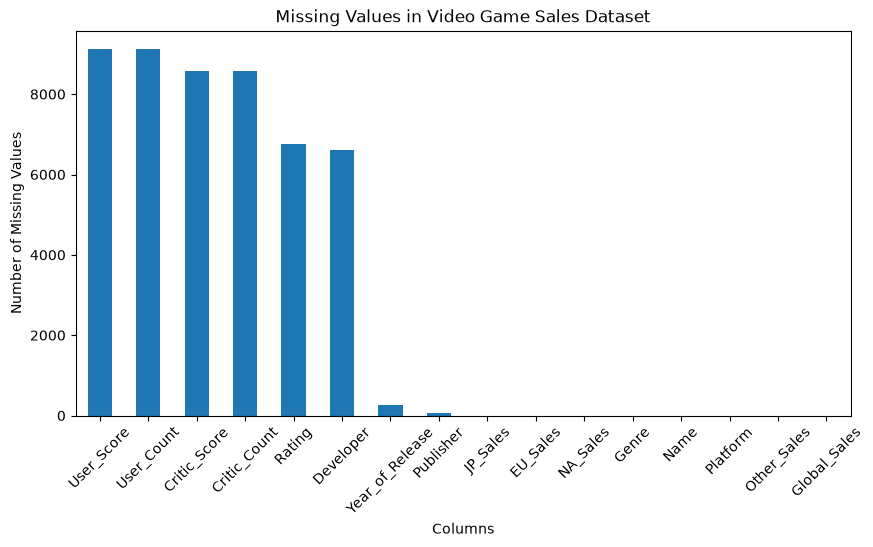

In [29]:
plt.figure(figsize=(10, 5))

df.isnull().sum().sort_values(
    ascending=False
).plot(kind='bar')

plt.title('Missing Values in Video Game Sales Dataset')
plt.xlabel('Columns')
plt.ylabel('Number of Missing Values')
plt.xticks(rotation=45)

plt.show()

Load the dataset.



Explore the dataset.



Check missing values.



Visualize the original data.



Check skewness of Global_Sales.



Handle missing values.



Split the data into training and testing sets (or split before fitting imputers).



Encode categorical features.



Train the model.

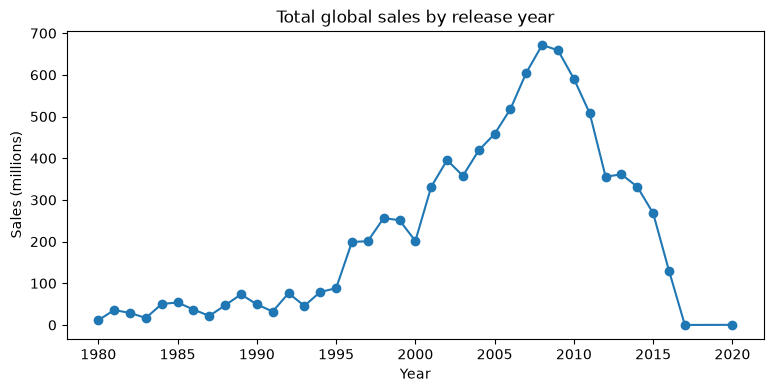

In [30]:
df.groupby("Year_of_Release")["Global_Sales"].sum().plot(kind="line", marker="o", figsize=(9, 4))
plt.title("Total global sales by release year")
plt.xlabel("Year")
plt.ylabel("Sales (millions)")
plt.show()

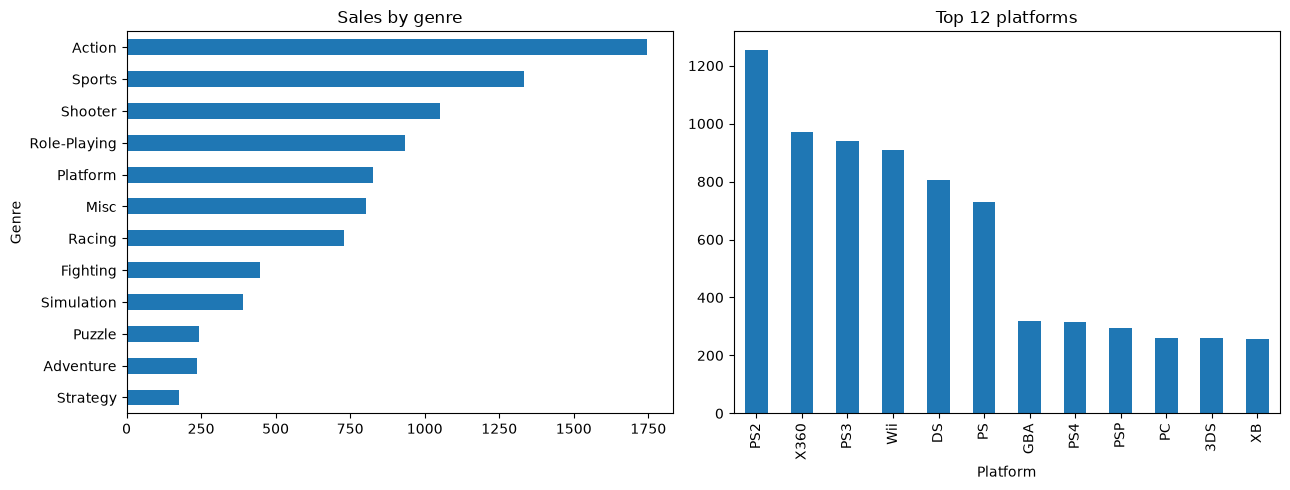

In [31]:

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
df.groupby("Genre")["Global_Sales"].sum().sort_values().plot(kind="barh", ax=ax[0], title="Sales by genre")
df.groupby("Platform")["Global_Sales"].sum().sort_values(ascending=False).head(12).plot(kind="bar", ax=ax[1], title="Top 12 platforms")
plt.tight_layout()
plt.show()

In [32]:
df.head()

,Name,Platform,Year_of_Release,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Critic_Score,Critic_Count,User_Score,User_Count,Developer,Rating
0,Wii Sports,Wii,2006.0,Sports,Nintendo,41.36,28.96,3.77,8.45,82.53,76.0,51.0,8.0,322.0,Nintendo,E
1,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24,NaN,NaN,NaN,NaN,NaN,NaN
2,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.68,12.76,3.79,3.29,35.52,82.0,73.0,8.3,709.0,Nintendo,E
3,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.61,10.93,3.28,2.95,32.77,80.0,73.0,8.0,192.0,Nintendo,E
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37,NaN,NaN,NaN,NaN,NaN,NaN


<Axes: xlabel='Rating'>

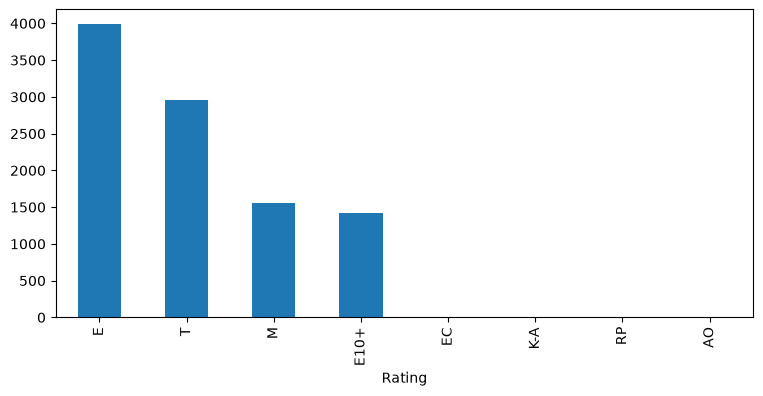

In [33]:
df.Rating.value_counts().plot(kind="bar", figsize=(9, 4))

In [34]:
print("Duplicate rows:", df.duplicated().sum())
print("Missing target values:", df["Global_Sales"].isna().sum())
print("Release year range:", df["Year_of_Release"].min(), "->", df["Year_of_Release"].max())

# tidy duplicate rating labels and keep the year as a whole number
df["Rating"] = df["Rating"].replace({"K-A": "E", "RP": "Unknown"})
df["Year_of_Release"] = df["Year_of_Release"].astype("Int64")

Duplicate rows: 0
Missing target values: 0
Release year range: 1980.0 -> 2020.0


## EDA

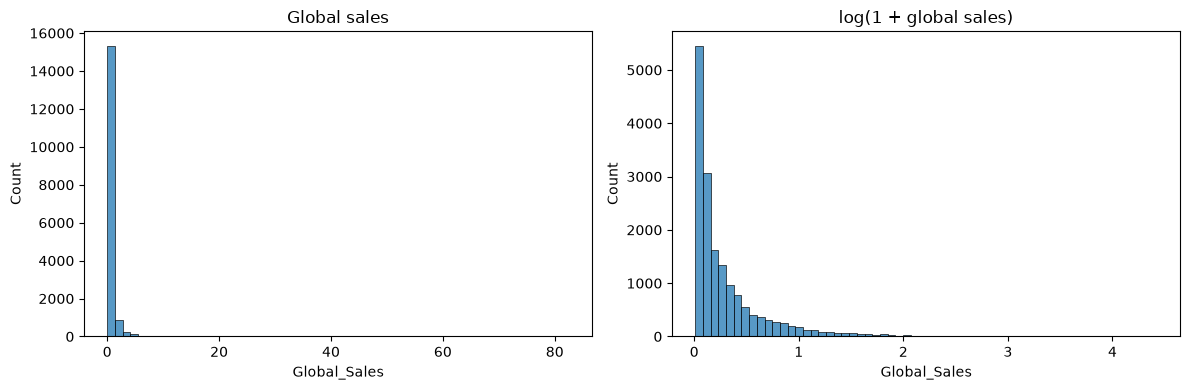

Skewness: 17.38


In [35]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["Global_Sales"], bins=60, ax=ax[0]).set_title("Global sales")
##log transormation to reduces the influence of very large values and makes the distribution easier to visualize.
sns.histplot(np.log1p(df["Global_Sales"]), bins=60, ax=ax[1]).set_title("log(1 + global sales)")
plt.tight_layout()
plt.show()
print("Skewness:", round(df["Global_Sales"].skew(), 2))

In [36]:
df["Global_Sales_log"] = np.log1p(df["Global_Sales"])

print("Original:", df["Global_Sales"].skew())
print("Transformed:", df["Global_Sales_log"].skew())

Original: 17.379414082230102
Transformed: 2.7618681168519696


Most games still have relatively low sales.
A few games have considerably higher sales.


log transformation has reduced skewness from 17.38 to 2.76 which Approximately 84.1% reduction in skewness ,so we found that  it imporves the distribution even though it hasnt made it symmetric.

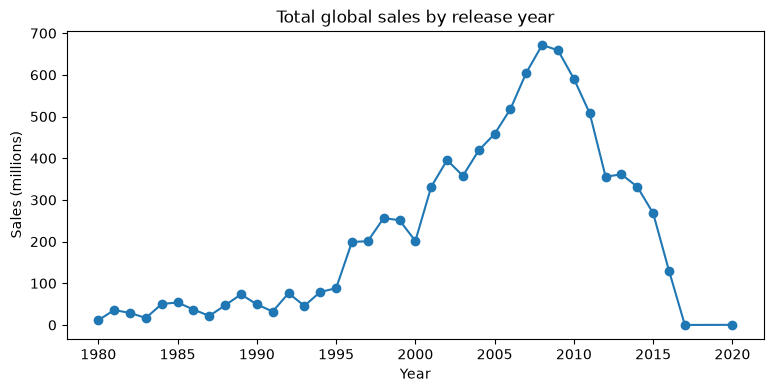

In [37]:
df.groupby("Year_of_Release")["Global_Sales"].sum().plot(
    kind="line",
    marker="o",
    figsize=(9, 4)
)

plt.title("Total global sales by release year")
plt.xlabel("Year")
plt.ylabel("Sales (millions)")
plt.show()

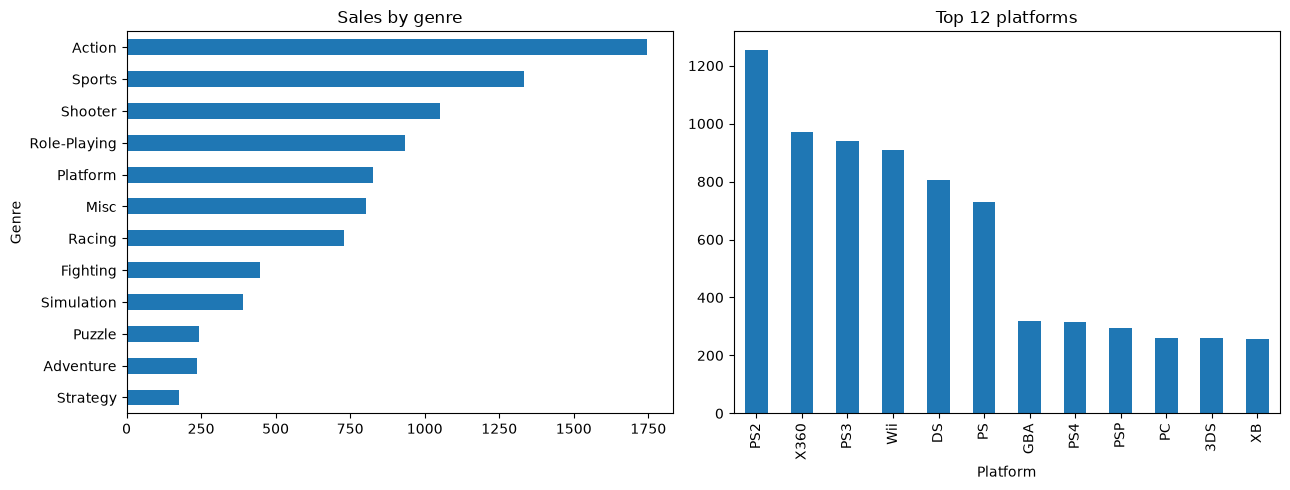

In [38]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
df.groupby("Genre")["Global_Sales"].sum().sort_values().plot(kind="barh", ax=ax[0], title="Sales by genre")
df.groupby("Platform")["Global_Sales"].sum().sort_values(ascending=False).head(12).plot(kind="bar", ax=ax[1], title="Top 12 platforms")
plt.tight_layout()
plt.show()

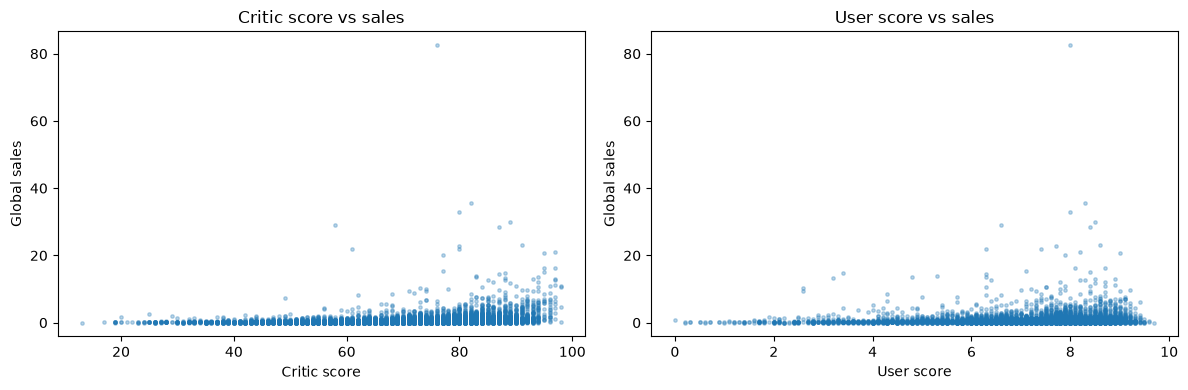

In [39]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(df["Critic_Score"], df["Global_Sales"], s=6, alpha=0.3)
ax[0].set(xlabel="Critic score", ylabel="Global sales", title="Critic score vs sales")
ax[1].scatter(df["User_Score"], df["Global_Sales"], s=6, alpha=0.3)
ax[1].set(xlabel="User score", ylabel="Global sales", title="User score vs sales")
plt.tight_layout()
plt.show()

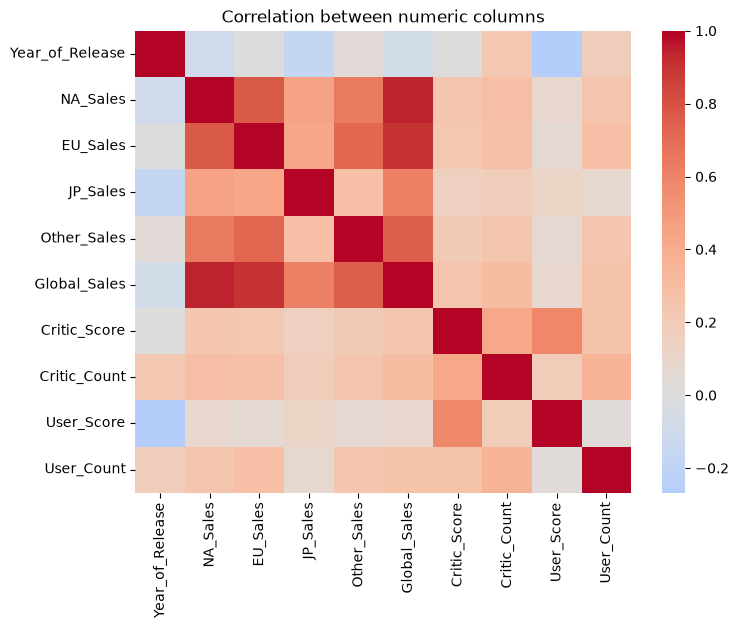

Share of rows where the regional sales rebuild Global_Sales: 0.729


In [40]:
num_cols = ["Year_of_Release", "NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales",
            "Global_Sales", "Critic_Score", "Critic_Count", "User_Score", "User_Count"]
plt.figure(figsize=(8, 6))
sns.heatmap(df[num_cols].corr(), cmap="coolwarm", center=0)
plt.title("Correlation between numeric columns")
plt.show()

# Global_Sales is the sum of the four regional columns, so they leak the target
regional = df[["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales"]].sum(axis=1)
print("Share of rows where the regional sales rebuild Global_Sales:",
      round((regional.round(2) == df["Global_Sales"].round(2)).mean(), 3))

## Feature engineering

In [41]:
reference_year=df["Year_of_Release"].max() 
reference_year

np.int64(2020)

In [42]:
df["Game_Age"] =reference_year - df["Year_of_Release"]
df["Has_Review_Scores"] = (
    df["Critic_Score"].notna() | df["User_Score"].notna()
).astype(int)
df["Review_Total_Count"] = df["Critic_Count"].fillna(0) + df["User_Count"].fillna(0)
df["Critic_User_Gap"] = df["User_Score"] * 10 - df["Critic_Score"] #bringing user score to the same scale as critic score by multiplying it by 10
df["Is_Major_Publisher"] = df["Publisher"].fillna("").str.contains(
    "Nintendo|Sony|Microsoft|Electronic Arts|Activision|Ubisoft", case=False
).astype(int)

df[["Game_Age", "Has_Review_Scores", "Review_Total_Count", "Critic_User_Gap", "Is_Major_Publisher"]].head()

,Game_Age,Has_Review_Scores,Review_Total_Count,Critic_User_Gap,Is_Major_Publisher
0,14,1,373.0,4.0,1
1,35,0,0.0,NaN,1
2,12,1,782.0,1.0,1
3,11,1,265.0,0.0,1
4,24,0,0.0,NaN,1


In [43]:
platform_groups = {
    # Nintendo
    "Wii": "Nintendo",
    "NES": "Nintendo",
    "GB": "Nintendo",
    "DS": "Nintendo",
    "SNES": "Nintendo",
    "GBA": "Nintendo",
    "3DS": "Nintendo",
    "N64": "Nintendo",
    "WiiU": "Nintendo",
    "GC": "Nintendo",

    # PlayStation
    "PS": "PlayStation",
    "PS2": "PlayStation",
    "PS3": "PlayStation",
    "PS4": "PlayStation",
    "PSP": "PlayStation",
    "PSV": "PlayStation",

    # Xbox
    "X360": "Xbox",
    "XB": "Xbox",
    "XOne": "Xbox",

    # PC
    "PC": "PC",

    # Sega
    "GEN": "Sega",
    "DC": "Sega",
    "SAT": "Sega",
    "SCD": "Sega",
    "GG": "Sega",

    # Atari
    "2600": "Atari",

    # Other platforms
    "WS": "Other",
    "NG": "Other",
    "TG16": "Other",
    "3DO": "Other",
    "PCFX": "Other"
}

df["Platform_Group"] = df["Platform"].map(platform_groups).fillna("Unknown")

In [44]:
print(df["Platform_Group"].value_counts())

Platform_Group
PlayStation    6723
Nintendo       6271
Xbox           2333
PC              974
Sega            259
Atari           133
Other            24
Name: count, dtype: int64


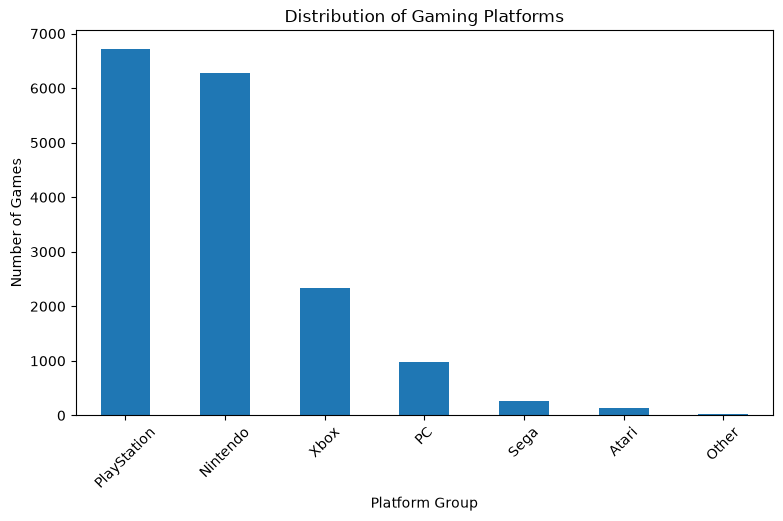

In [45]:
import matplotlib.pyplot as plt

df["Platform_Group"].value_counts().plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Distribution of Gaming Platforms")
plt.xlabel("Platform Group")
plt.ylabel("Number of Games")
plt.xticks(rotation=45)
plt.show()

In [46]:
df.columns

Index(['Name', 'Platform', 'Year_of_Release', 'Genre', 'Publisher', 'NA_Sales',
       'EU_Sales', 'JP_Sales', 'Other_Sales', 'Global_Sales', 'Critic_Score',
       'Critic_Count', 'User_Score', 'User_Count', 'Developer', 'Rating',
       'Global_Sales_log', 'Game_Age', 'Has_Review_Scores',
       'Review_Total_Count', 'Critic_User_Gap', 'Is_Major_Publisher',
       'Platform_Group'],
      dtype='str')

In [47]:
df.head(1)

,Name,Platform,Year_of_Release,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,...,User_Count,Developer,Rating,Global_Sales_log,Game_Age,Has_Review_Scores,Review_Total_Count,Critic_User_Gap,Is_Major_Publisher,Platform_Group
0,Wii Sports,Wii,2006,Sports,Nintendo,41.36,28.96,3.77,8.45,82.53,...,322.0,Nintendo,E,4.425206,14,1,373.0,4.0,1,Nintendo


## Train test split

In [48]:
from sklearn.model_selection import train_test_split

# Features available in the selected post-review prediction scenario.
numeric_features = [
    "Game_Age",
    "Year_of_Release",
    "Has_Review_Scores",
    "Review_Total_Count",
    "Critic_User_Gap",
    "Critic_Score",
    "Critic_Count",
    "User_Score",
    "User_Count",
    "Is_Major_Publisher"
]

categorical_features = [
    "Platform",
    "Genre",
    "Rating",
    "Publisher",
    "Developer"
]

features = numeric_features + categorical_features
target = "Global_Sales"

X = df[features].copy()
y = df[target].copy()

# Random holdout for a comparable baseline benchmark.
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])
print("Training features:", X_train.shape[1])


Training rows: 13373
Testing rows: 3344
Training features: 15


In [49]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# Separate numeric and categorical columns.
X_train_num = X_train[numeric_features].copy()
X_test_num = X_test[numeric_features].copy()
X_train_cat = X_train[categorical_features].copy()
X_test_cat = X_test[categorical_features].copy()

# Fit imputers on training data only.
numeric_imputer = SimpleImputer(strategy="median")
categorical_imputer = SimpleImputer(strategy="constant", fill_value="Unknown")

X_train_num = pd.DataFrame(
    numeric_imputer.fit_transform(X_train_num),
    columns=numeric_features,
    index=X_train.index
)
X_test_num = pd.DataFrame(
    numeric_imputer.transform(X_test_num),
    columns=numeric_features,
    index=X_test.index
)

X_train_cat = pd.DataFrame(
    categorical_imputer.fit_transform(X_train_cat),
    columns=categorical_features,
    index=X_train.index
)
X_test_cat = pd.DataFrame(
    categorical_imputer.transform(X_test_cat),
    columns=categorical_features,
    index=X_test.index
)

# Fit one-hot encoding on training categories only.
encoder = OneHotEncoder(
    handle_unknown="ignore",
    min_frequency=10,
    sparse_output=False
)

X_train_encoded = encoder.fit_transform(X_train_cat)
X_test_encoded = encoder.transform(X_test_cat)

encoded_columns = encoder.get_feature_names_out(categorical_features)

X_train_processed = pd.concat(
    [
        X_train_num,
        pd.DataFrame(X_train_encoded, columns=encoded_columns, index=X_train.index)
    ],
    axis=1
)

X_test_processed = pd.concat(
    [
        X_test_num,
        pd.DataFrame(X_test_encoded, columns=encoded_columns, index=X_test.index)
    ],
    axis=1
)

# Log-transform the target to reduce the influence of very high-sales games.
y_train_log = np.log1p(y_train)
y_test_log = np.log1p(y_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)


Processed training shape: (13373, 380)
Processed testing shape: (3344, 380)


In [50]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

models = {
    "Linear Regression": LinearRegression(),
   
    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        min_samples_split=5,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )
}



try:
    from xgboost import XGBRegressor
    models["XGBoost"] = XGBRegressor(
        n_estimators=400,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )
except ImportError:
    print("XGBoost is not installed. Run: pip install xgboost")



trained_models = {}

for name, model in models.items():
    model.fit(X_train_processed, y_train_log)
    trained_models[name] = model

print("Models trained:", list(trained_models.keys()))


Models trained: ['Linear Regression', 'Random Forest', 'XGBoost']


In [51]:
results = []

for name, model in trained_models.items():
    predictions_log = model.predict(X_test_processed)
    predictions = np.maximum(np.expm1(predictions_log), 0)

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2": r2_score(y_test, predictions)
    })

results_df = pd.DataFrame(results).sort_values("MAE")
display(results_df)

best_initial_name = results_df.iloc[0]["Model"]
print("Best initial model:", best_initial_name)


,Model,MAE,RMSE,R2
2,XGBoost,0.361110,1.667797,0.326471
1,Random Forest,0.372364,1.758378,0.251323
0,Linear Regression,0.419670,1.852057,0.169425


Best initial model: XGBoost


In [52]:
# Select the best-performing model from the comparison table.
best_initial_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_initial_name]

print("Best model based on test MAE:", best_initial_name)


Best model based on test MAE: XGBoost


In [53]:
best_predictions_log = best_model.predict(X_test_processed)
best_predictions = np.maximum(np.expm1(best_predictions_log), 0)

best_result = pd.DataFrame([{
    "Model": best_initial_name,
    "MAE": mean_absolute_error(y_test, best_predictions),
    "RMSE": np.sqrt(mean_squared_error(y_test, best_predictions)),
    "R2": r2_score(y_test, best_predictions)
}])

display(best_result)


,Model,MAE,RMSE,R2
0,XGBoost,0.36111,1.667797,0.326471


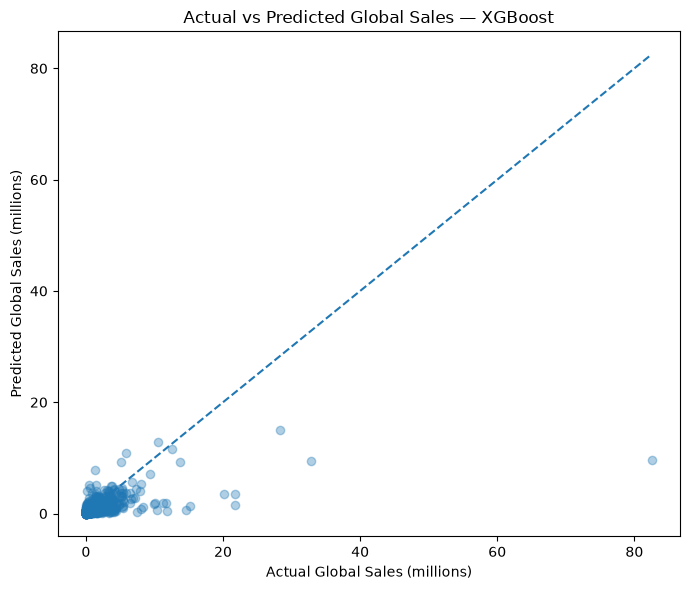

In [54]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, best_predictions, alpha=0.35)
limit = max(float(y_test.max()), float(best_predictions.max()))
plt.plot([0, limit], [0, limit], linestyle="--")
plt.xlabel("Actual Global Sales (millions)")
plt.ylabel("Predicted Global Sales (millions)")
plt.title(f"Actual vs Predicted Global Sales — {best_initial_name}")
plt.tight_layout()
plt.show()


,Feature,Importance,Importance_Std
3,Review_Total_Count,0.040927,0.001980
8,User_Count,0.036432,0.001234
20,Platform_PC,0.024574,0.000641
0,Game_Age,0.019935,0.000714
9,Is_Major_Publisher,0.011382,0.000781
5,Critic_Score,0.008615,0.000101
138,Publisher_Nintendo,0.006554,0.000734
22,Platform_PS2,0.003398,0.000445
169,Publisher_THQ,0.003186,0.000397
47,Rating_E,0.003022,0.000226


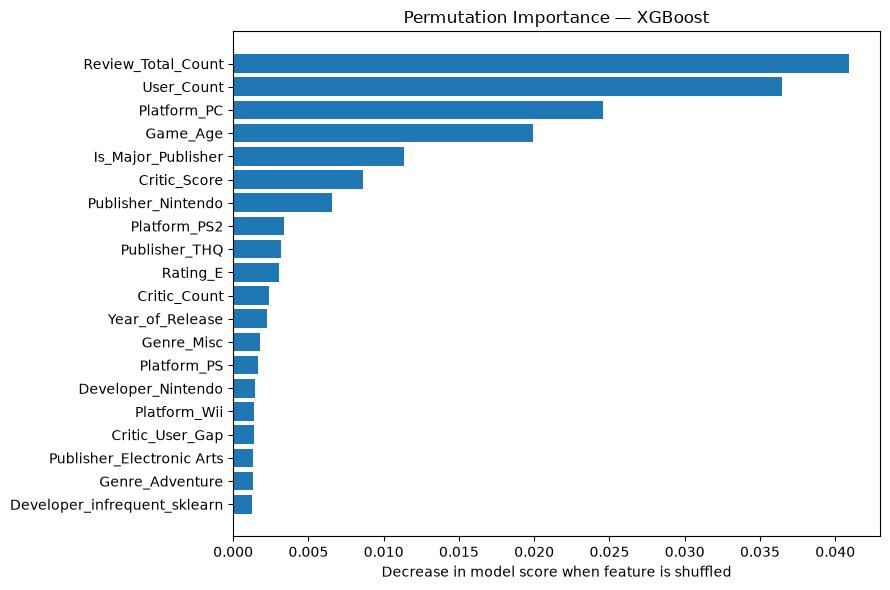

In [55]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    best_model,
    X_test_processed,
    y_test_log,
    scoring="neg_mean_absolute_error",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_test_processed.columns,
    "Importance": perm.importances_mean,
    "Importance_Std": perm.importances_std
}).sort_values("Importance", ascending=False)

display(importance_df.head(20))

plt.figure(figsize=(9, 6))
top_features = importance_df.head(20).sort_values("Importance")
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Decrease in model score when feature is shuffled")
plt.title(f"Permutation Importance — {best_initial_name}")
plt.tight_layout()
plt.show()


In [56]:
xgb_model = XGBRegressor(
    objective="reg:squarederror",
    random_state=42,
    n_jobs=1
)

In [57]:
param_grid = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [3, 4, 5, 6, 8],
    "learning_rate": [0.01, 0.03, 0.05, 0.1, 0.2],
    "subsample": [0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "min_child_weight": [1, 3, 5, 7],
    "gamma": [0, 0.1, 0.2, 0.3],
    "reg_alpha": [0, 0.01, 0.1, 1],
    "reg_lambda": [1, 2, 5, 10]
}

In [58]:
from sklearn.model_selection import RandomizedSearchCV
random_search = RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=param_grid,
    n_iter=30,
    scoring="neg_root_mean_squared_error",
    cv=5,
    verbose=1,
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_train_processed, y_train)

Fitting 5 folds for each of 30 candidates, totalling 150 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBRegressor(...ree=None, ...)"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'colsample_bytree': [0.7, 0.8, ...], 'gamma': [0, 0.1, ...], 'learning_rate': [0.01, 0.03, ...], 'max_depth': [3, 4, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",30
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to 

In [59]:
print("Best Parameters:")
print(random_search.best_params_)

print("\nBest Cross-Validation RMSE:")
print(-random_search.best_score_)

Best Parameters:
{'subsample': 1.0, 'reg_lambda': 1, 'reg_alpha': 1, 'n_estimators': 300, 'min_child_weight': 3, 'max_depth': 6, 'learning_rate': 0.1, 'gamma': 0.1, 'colsample_bytree': 0.8}

Best Cross-Validation RMSE:
1.068352559208806


In [60]:
best_xgb_model = random_search.best_estimator_

y_pred_tuned = best_xgb_model.predict(X_test_processed)

mae = mean_absolute_error(y_test, y_pred_tuned)
rmse = np.sqrt(mean_squared_error(y_test, y_pred_tuned))
r2 = r2_score(y_test, y_pred_tuned)

print("Tuned XGBoost Performance")
print("-------------------------")
print("MAE:", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)

Tuned XGBoost Performance
-------------------------
MAE: 0.39766786707080953
RMSE: 1.5356244369140373
R2 Score: 0.4289945920299393


In [61]:
comparison = pd.DataFrame({
    "Model": ["XGBoost Before Tuning", "XGBoost After Tuning"],
    "MAE": [0.361110, mae],
    "RMSE": [1.667797, rmse],
    "R2": [0.326471, r2]
})

display(comparison)

,Model,MAE,RMSE,R2
0,XGBoost Before Tuning,0.361110,1.667797,0.326471
1,XGBoost After Tuning,0.397668,1.535624,0.428995


## check check dont go down


In [62]:
# from sklearn.model_selection import train_test_split

# features = ["Game_Age", "Has_Review_Scores", "Review_Total_Count",
#             "Critic_User_Gap", "Critic_Score", "Critic_Count", "User_Score", "User_Count",
#             "Is_Major_Publisher", "Platform_Group", "Genre", "Rating", "Publisher", "Developer"]
# target = "Global_Sales"

# X_train, X_test, y_train, y_test = train_test_split(
#     df[features], df[target], test_size=0.2, random_state=42)
# X_train = X_train.copy()
# X_test = X_test.copy()
# print("Train:", X_train.shape, " Test:", X_test.shape)